# Ch. 3.7 #4, 7 and Applied Exercise 10

4.<br>(a)

The training RSS for the cubic model should be lower (or at worst, equal to). The linear model is nested within the cube one (where we set both coeffecients to 0), and the lesat squares minimizes RSS over all the parameters. So the cubic fit can never do worse on the training data. It should fit some of the noise too, which will push RSS down further.

(b)

The linear model should have a lower test RSS. The cubic model has overfit the noise in the training set, so it will add variance without reeducing bias.

(c)

The cubic model has lower training RSS because it has the same nesting behavior, unlike the linear.

7.

![prob7](problem-7.jpeg)

10.

In [3]:
install.packages("ISLR2")
library(ISLR2)   # or library(ISLR); both contain Carseats
data(Carseats)


The downloaded binary packages are in
	/var/folders/rk/hm976cm116b00fkw44hrlkgc0000gn/T//RtmpyO4FHe/downloaded_packages


(a)

In [4]:
fit_full <- lm(Sales ~ Price + Urban + US, data = Carseats)
summary(fit_full)


Call:
lm(formula = Sales ~ Price + Urban + US, data = Carseats)

Residuals:
    Min      1Q  Median      3Q     Max 
-6.9206 -1.6220 -0.0564  1.5786  7.0581 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 13.043469   0.651012  20.036  < 2e-16 ***
Price       -0.054459   0.005242 -10.389  < 2e-16 ***
UrbanYes    -0.021916   0.271650  -0.081    0.936    
USYes        1.200573   0.259042   4.635 4.86e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.472 on 396 degrees of freedom
Multiple R-squared:  0.2393,	Adjusted R-squared:  0.2335 
F-statistic: 41.52 on 3 and 396 DF,  p-value: < 2.2e-16


(b)

In [5]:
# Check how R coded the qualitative variables (reference levels are "No")
contrasts(Carseats$Urban)
contrasts(Carseats$US)

coef(fit_full)
# Price:    change in Sales (thousands) per $1 increase in Price, holding Urban and US fixed
# UrbanYes: urban minus rural difference in Sales, holding Price and US fixed
# USYes:    US minus non-US difference in Sales, holding Price and Urban fixed

,Yes
No,0
Yes,1


,Yes
No,0
Yes,1


(Intercept)       Price    UrbanYes       USYes 
13.04346894 -0.05445885 -0.02191615  1.20057270

(c)

In [6]:
b <- round(coef(fit_full), 4)
cat(sprintf(
  "Sales = %.4f + (%.4f)*Price + (%.4f)*Urban[Yes] + (%.4f)*US[Yes]\n",
  b["(Intercept)"], b["Price"], b["UrbanYes"], b["USYes"]
))
# Urban[Yes] = 1 if the store is urban, 0 if rural
# US[Yes]    = 1 if the store is in the US, 0 otherwise

Sales = 13.0435 + (-0.0545)*Price + (-0.0219)*Urban[Yes] + (1.2006)*US[Yes]


(d)

In [7]:
coef_tab <- summary(fit_full)$coefficients
coef_tab
coef_tab[, "Pr(>|t|)"] < 0.05   # TRUE = reject H0 at the 5% level

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),13.04346894,0.651012245,20.03567373,3.626602e-62
Price,-0.05445885,0.005241855,-10.38923205,1.609917e-22
UrbanYes,-0.02191615,0.271650277,-0.08067781,9.357389e-01
USYes,1.20057270,0.259041508,4.63467306,4.860245e-06


(Intercept)       Price    UrbanYes       USYes 
       TRUE        TRUE       FALSE        TRUE

(e)

In [8]:
fit_small <- lm(Sales ~ Price + US, data = Carseats)
summary(fit_small)


Call:
lm(formula = Sales ~ Price + US, data = Carseats)

Residuals:
    Min      1Q  Median      3Q     Max 
-6.9269 -1.6286 -0.0574  1.5766  7.0515 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 13.03079    0.63098  20.652  < 2e-16 ***
Price       -0.05448    0.00523 -10.416  < 2e-16 ***
USYes        1.19964    0.25846   4.641 4.71e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.469 on 397 degrees of freedom
Multiple R-squared:  0.2393,	Adjusted R-squared:  0.2354 
F-statistic: 62.43 on 2 and 397 DF,  p-value: < 2.2e-16


(f)

In [9]:
fit_stats <- function(m) {
  s <- summary(m)
  c(R2 = s$r.squared,
    Adj_R2 = s$adj.r.squared,
    RSE = s$sigma,
    F = unname(s$fstatistic["value"]))
}
rbind(full = fit_stats(fit_full), small = fit_stats(fit_small))

anova(fit_small, fit_full)   # F-test: does adding Urban improve the fit?

,R2,Adj_R2,RSE,F
full,0.2392754,0.2335123,2.472492,41.51877
small,0.2392629,0.2354305,2.469397,62.43114


,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,397,2420.874,NA,NA,NA,NA
2,396,2420.835,1,0.03979039,0.00650891,0.9357389


(g)

In [10]:
confint(fit_small, level = 0.95)

,2.5 %,97.5 %
(Intercept),11.79032020,14.27126531
Price,-0.06475984,-0.04419543
USYes,0.69151957,1.70776632


(h)

[1] 2.891521

named integer(0)

[1] 0.04333766

43 126 166 175 314 368 
 43 126 166 175 314 368

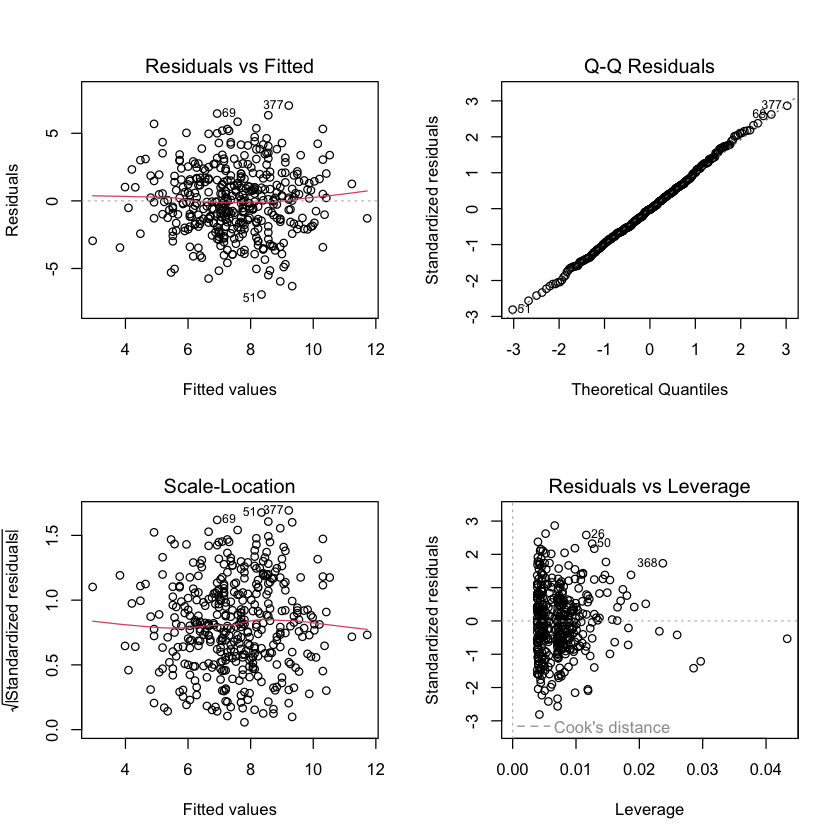

[1] 0.02610946

26 
26

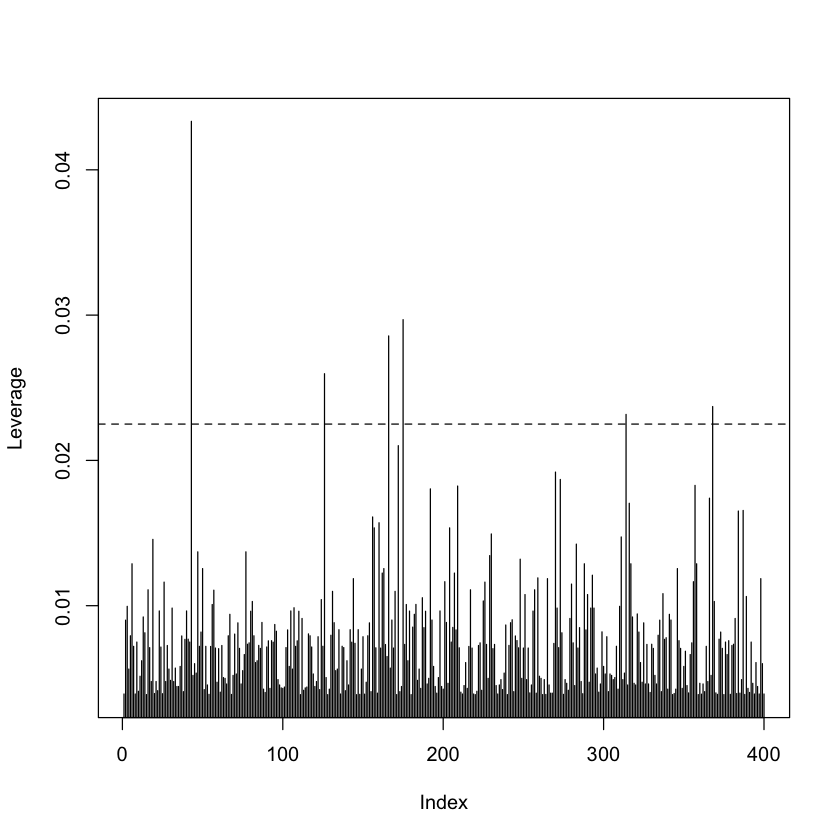

In [11]:
par(mfrow = c(2, 2))
plot(fit_small)
par(mfrow = c(1, 1))

# Outliers: studentized residuals beyond +/- 3
stud_res <- rstudent(fit_small)
max(abs(stud_res))
which(abs(stud_res) > 3)

# High leverage: compare to the average leverage (p + 1) / n
lev <- hatvalues(fit_small)
avg_lev <- mean(lev)                     # equals (p + 1) / n = 3 / 400
max(lev)
which(lev > 3 * avg_lev)                 # common rule-of-thumb cutoff
plot(lev, type = "h", ylab = "Leverage"); abline(h = 3 * avg_lev, lty = 2)

# Influence: Cook's distance (values near or above 1 are a concern)
cd <- cooks.distance(fit_small)
max(cd)
which.max(cd)